# Task 2.3: read the memory bit through the buffer

The aim is to distinguish the two memory codewords through the emitted buffer field. A weak memory drive maps their signs into opposite real buffer amplitudes, providing a transmon-free readout signal. We test the leading contrast estimate and determine how long the response takes to settle.

$$H=H_{2\mathrm{ph}}+\epsilon_Z(a+a^\dagger),\qquad \epsilon_Z/g_2=0.05.$$

We choose a drive well below $g_2$ to probe the approximately linear response while keeping the displacement about the occupied well small. With the supplied parameters, $\epsilon_Z=0.23970$ µs⁻¹, $\alpha=2.1$, and $\epsilon_Z/(2\pi)=38.15$ kHz. Both loss channels are retained. Each codeword is initialized with the buffer in vacuum; preparation errors are excluded. The drive sweep tests linearity. Readout-strength optimization and its effect on bit-flip protection belong to Task 2.4.

In [1]:
import sys, json, io
from pathlib import Path
from contextlib import redirect_stdout
from IPython.display import Image, Markdown, display
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'src/config.py').is_file() and (p / 'docs/challenge_prompt_v4.md').is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
show = lambda name, w=1050: display(Image(filename=str(ROOT / 'figures' / f'{name}.png'), width=w))


In [2]:
RERUN = False
if RERUN:
    from tasks import task_2_3
    with redirect_stdout(io.StringIO()):
        task_2_3.main()
r = json.loads((ROOT / 'results/task_2_3.json').read_text())
p = r['configuration']
s = next(row for row in r['drive_summaries'] if row['drive_ratio'] == p['nominal_drive_ratio'])


## Buffer fields and readout contrast

For $s=\pm1$, let $\rho_s(t)$ be the joint memory–buffer density matrix evolved from $|s\alpha\rangle_a|0\rangle_b$. Define the memory amplitude $A_s(t)=\mathrm{Tr}(a\rho_s(t))$ and buffer field $\beta_s(t)=\mathrm{Tr}(b\rho_s(t))$.

The drive contributes $\dot A_s=-i\epsilon_Z$, displacing the memory along the imaginary axis. Write $A_s=s\alpha+\delta a_s$, where $\delta a_s$ is the displacement from the occupied well. The local semiclassical expansion $A_s^2-\alpha^2\simeq2s\alpha\delta a_s$ makes the buffer response depend on the codeword sign. Neglecting memory loss, it gives

$$\beta_s\simeq-\frac{s\epsilon_Z}{2\alpha g_2}.$$

Let $\bar\beta_s$ be each branch's complex mean over 3–4 µs. The plateau contrast is $\Delta\beta_R=\mathrm{Re}(\bar\beta_--\bar\beta_+)$; the common field is $\beta_{\mathrm{com}}(t)=(\beta_+(t)+\beta_-(t))/2$. Memory loss generates a common imaginary component. The exact symmetry $\beta_-=-\beta_+^*$ gives opposite real fields and equal imaginary fields; both codewords are evolved independently to test this relation. These means describe the finite observation interval.

In [3]:
import pandas as pd
branches = pd.DataFrame([
    {'initial memory': '+alpha', 'Re <b>': s['beta_plus'][0], 'Im <b>': s['beta_plus'][1]},
    {'initial memory': '-alpha', 'Re <b>': s['beta_minus'][0], 'Im <b>': s['beta_minus'][1]},
])
display(branches.style.format({'Re <b>': '{:.8f}', 'Im <b>': '{:.8f}'}))
display(Markdown(f"Real separation **{s['real_separation']:.8f}**, versus **{s['leading_separation']:.8f}** predicted; relative difference **{100*s['relative_contrast_error']:.4f}%**."))


,initial memory,Re,Im
0,+alpha,-0.01189484,0.00311514
1,-alpha,0.01189484,0.00311514


Real separation **0.02378968**, versus **0.02380952** predicted; relative difference **-0.0834%**.

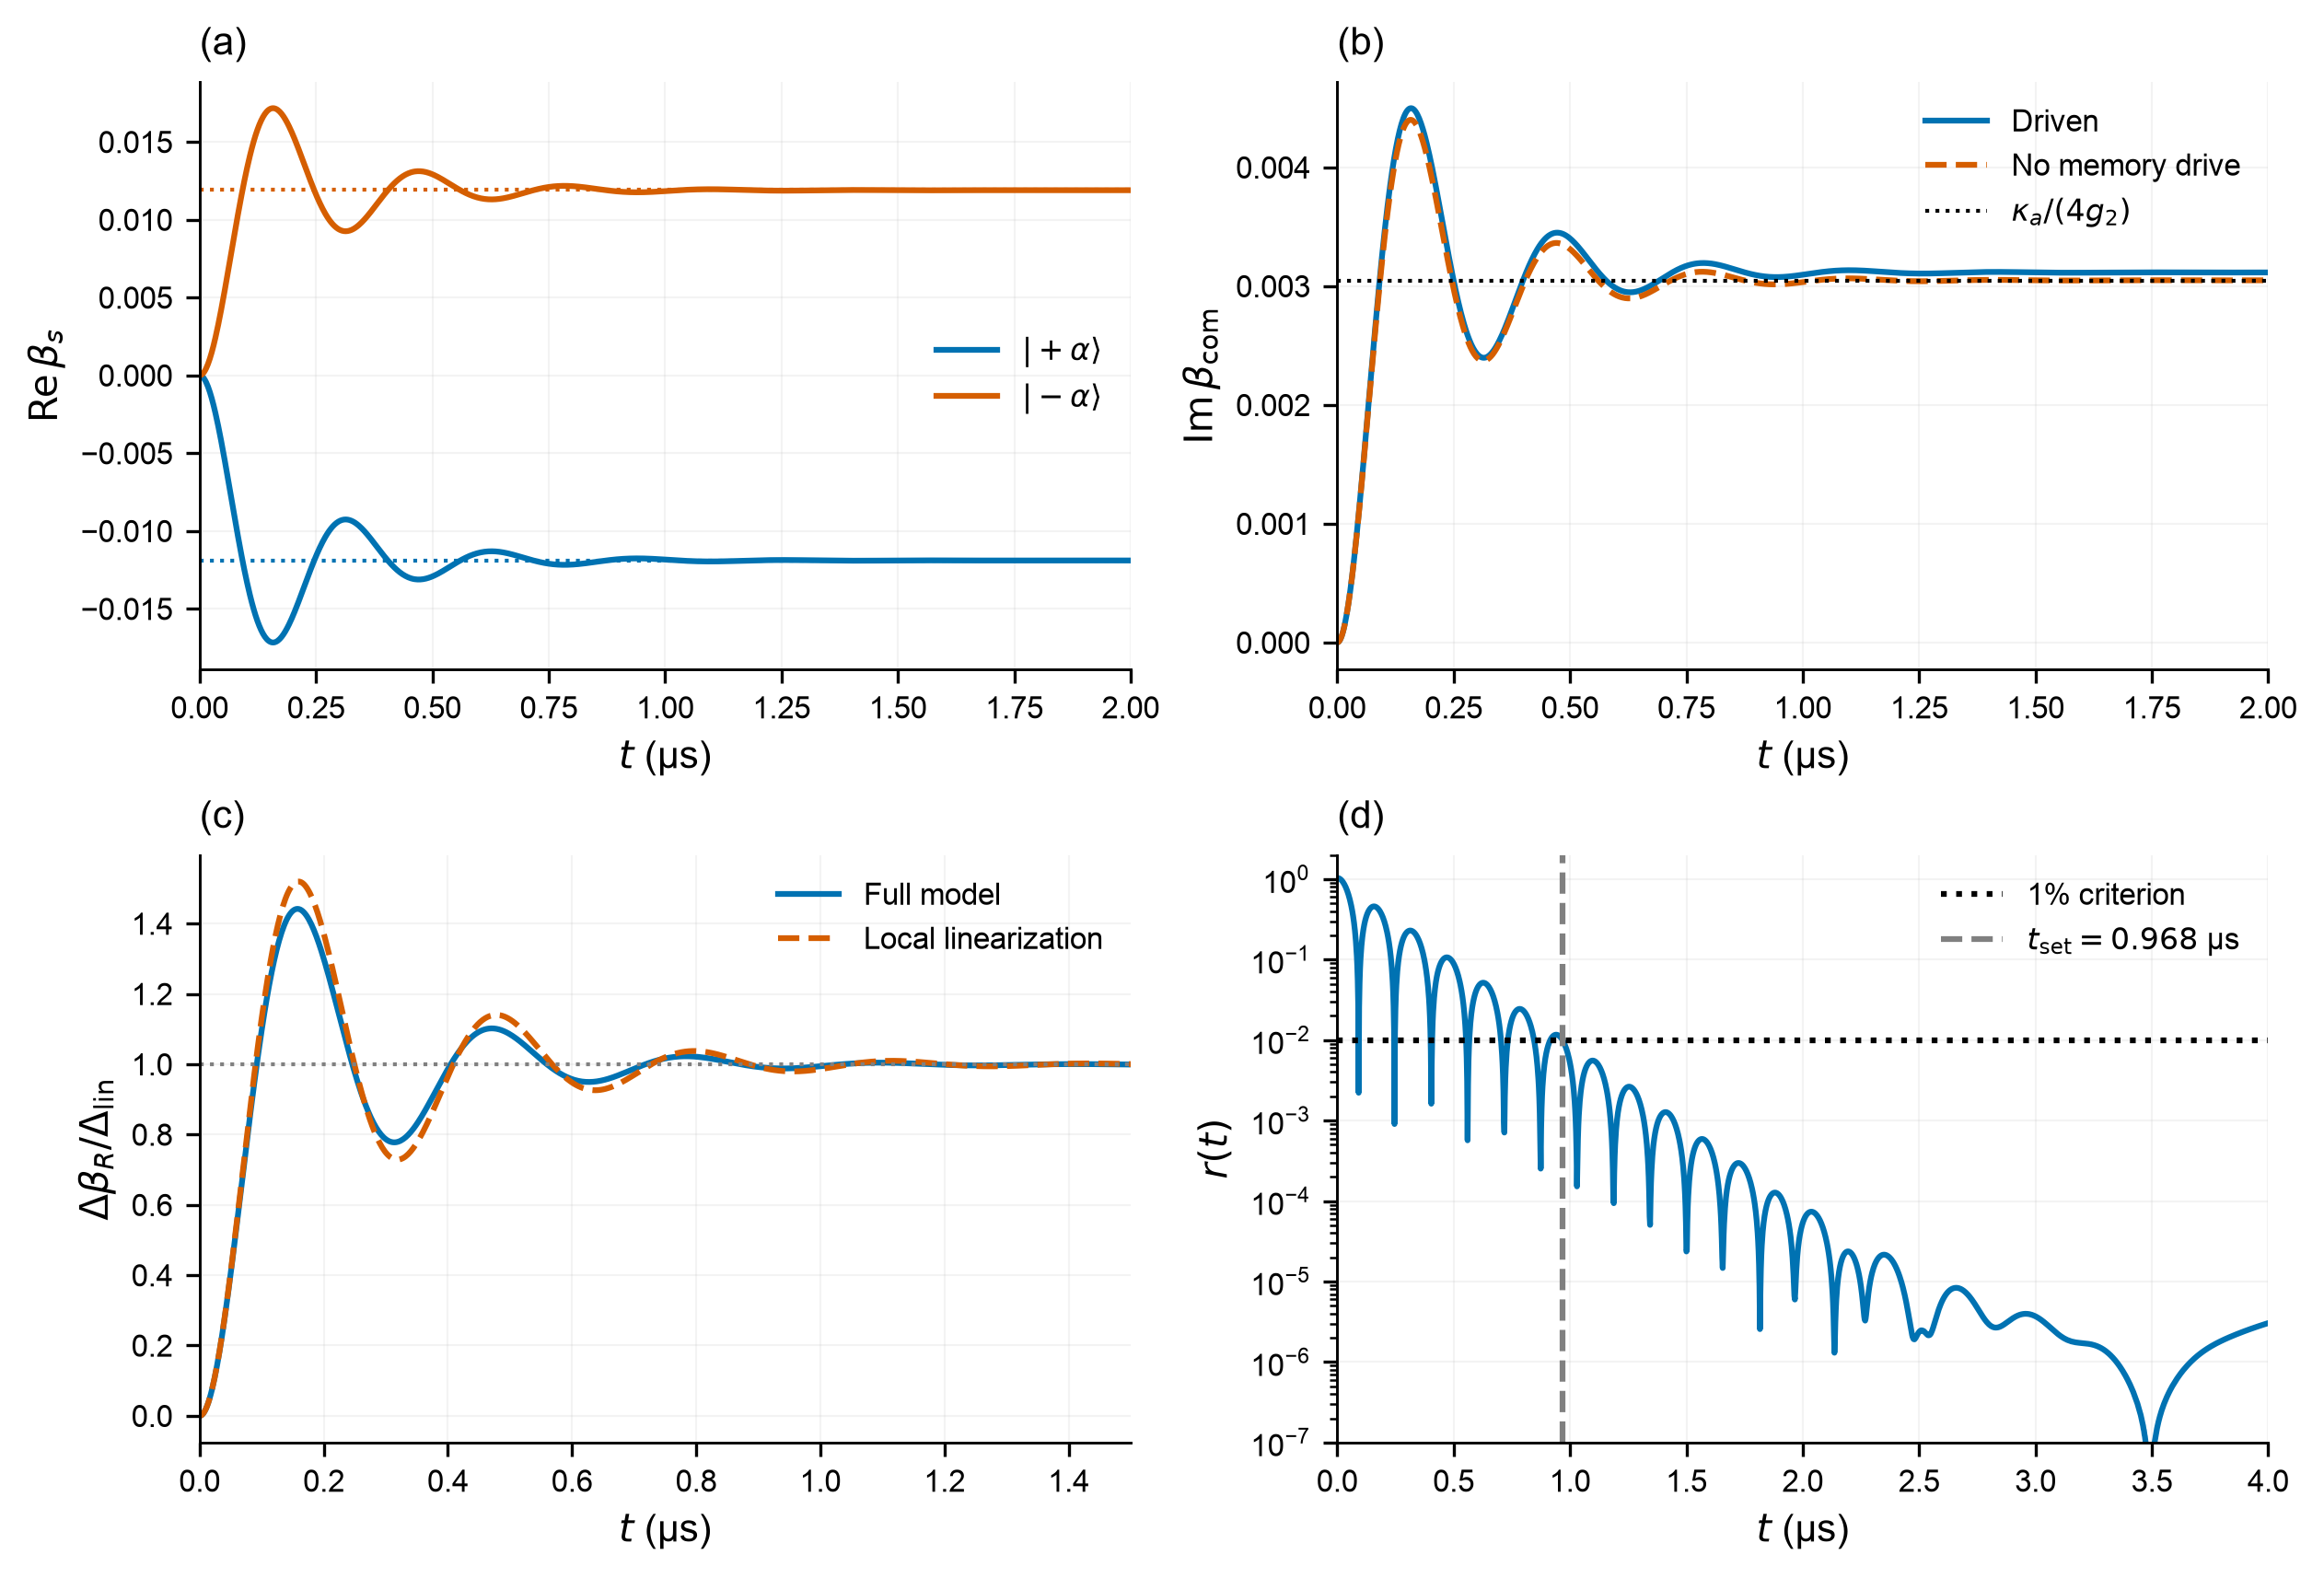

In [4]:
show('task_2_3_readout')

**Weak-drive memory-bit readout.** Both initial memory codewords $\lvert s\alpha\rangle$, $s=\pm1$, evolve independently with a vacuum buffer, $\alpha=2.1$, $(N_a,N_b)=(32,12)$ and the constant drive $\epsilon_Z(a+a^\dagger)$ at $\epsilon_Z/g_2=0.05$. Define $\beta_s=\langle b\rangle_s$. (a) Real buffer fields; dotted lines give the leading estimates $-s\epsilon_Z/(2\alpha g_2)$. (b) Imaginary common field $\beta_{\mathrm{com}}=(\beta_++\beta_-)/2$, compared with the zero-drive control and the leading memory-loss contribution $\kappa_a/(4g_2)$. (c) Real separation $\Delta\beta_R(t)=\mathrm{Re}(\beta_--\beta_+)$ divided by $\Delta_{\mathrm{lin}}=\epsilon_Z/(\alpha g_2)$; dashes show local semiclassical linearization including memory loss. (d) Residual $r(t)$ is the larger complex-field distance from the two 3–4 µs means, divided by $\epsilon_Z/(2\alpha g_2)$. Dotted and dashed guides mark $r=0.01$ and $t_{\mathrm{set}}=0.968$ µs, respectively. Both fields satisfy the criterion from this time through 4 µs. Saved times are 2 ns apart.

## Settling and oscillation

Define the normalized complex-field residual

$$r(t)=\frac{\max_{s=\pm}|\beta_s(t)-\bar\beta_s|}{\epsilon_Z/(2\alpha g_2)}.$$

The settling time $t_{\mathrm{set}}$ is the first saved time after which $r(t)\leq0.01$ at every remaining sample through 4 µs. Using the last violation excludes early threshold crossings followed by further ringing. This criterion includes both quadratures. An 8-µs run checks the result against a later 7–8 µs mean; the 2-ns save grid is distinct from adaptive integration steps.

The local semiclassical eigenvalues are $-(\kappa_a+\kappa_b)/4\pm i\omega$, with $\omega^2=(2g_2\alpha)^2-[(\kappa_b-\kappa_a)/4]^2$. They predict damped oscillation with a 0.319-µs period and a 0.244-µs envelope time. The full quantum response determines the reported settling time.

In [5]:
display(Markdown(
    f"The first contrast maximum occurs at **{s['first_peak_us']:.3f} µs**, with **{100*s['overshoot_fraction']:.1f}%** overshoot. "
    f"The measured peak-spacing period is approximately **{s['ring_period_us']:.3f} µs**. "
    f"Both complex fields stay inside the criterion from **{s['settling_time_us']:.3f} µs** through 4 µs; "
    f"the sampled crossing is bracketed by **{s['settling_bracket_us']} µs**."
))


The first contrast maximum occurs at **0.158 µs**, with **44.3%** overshoot. The measured peak-spacing period is approximately **0.313 µs**. Both complex fields stay inside the criterion from **0.968 µs** through 4 µs; the sampled crossing is bracketed by **[0.966, 0.968] µs**.

## Linearity, controls and numerical validation

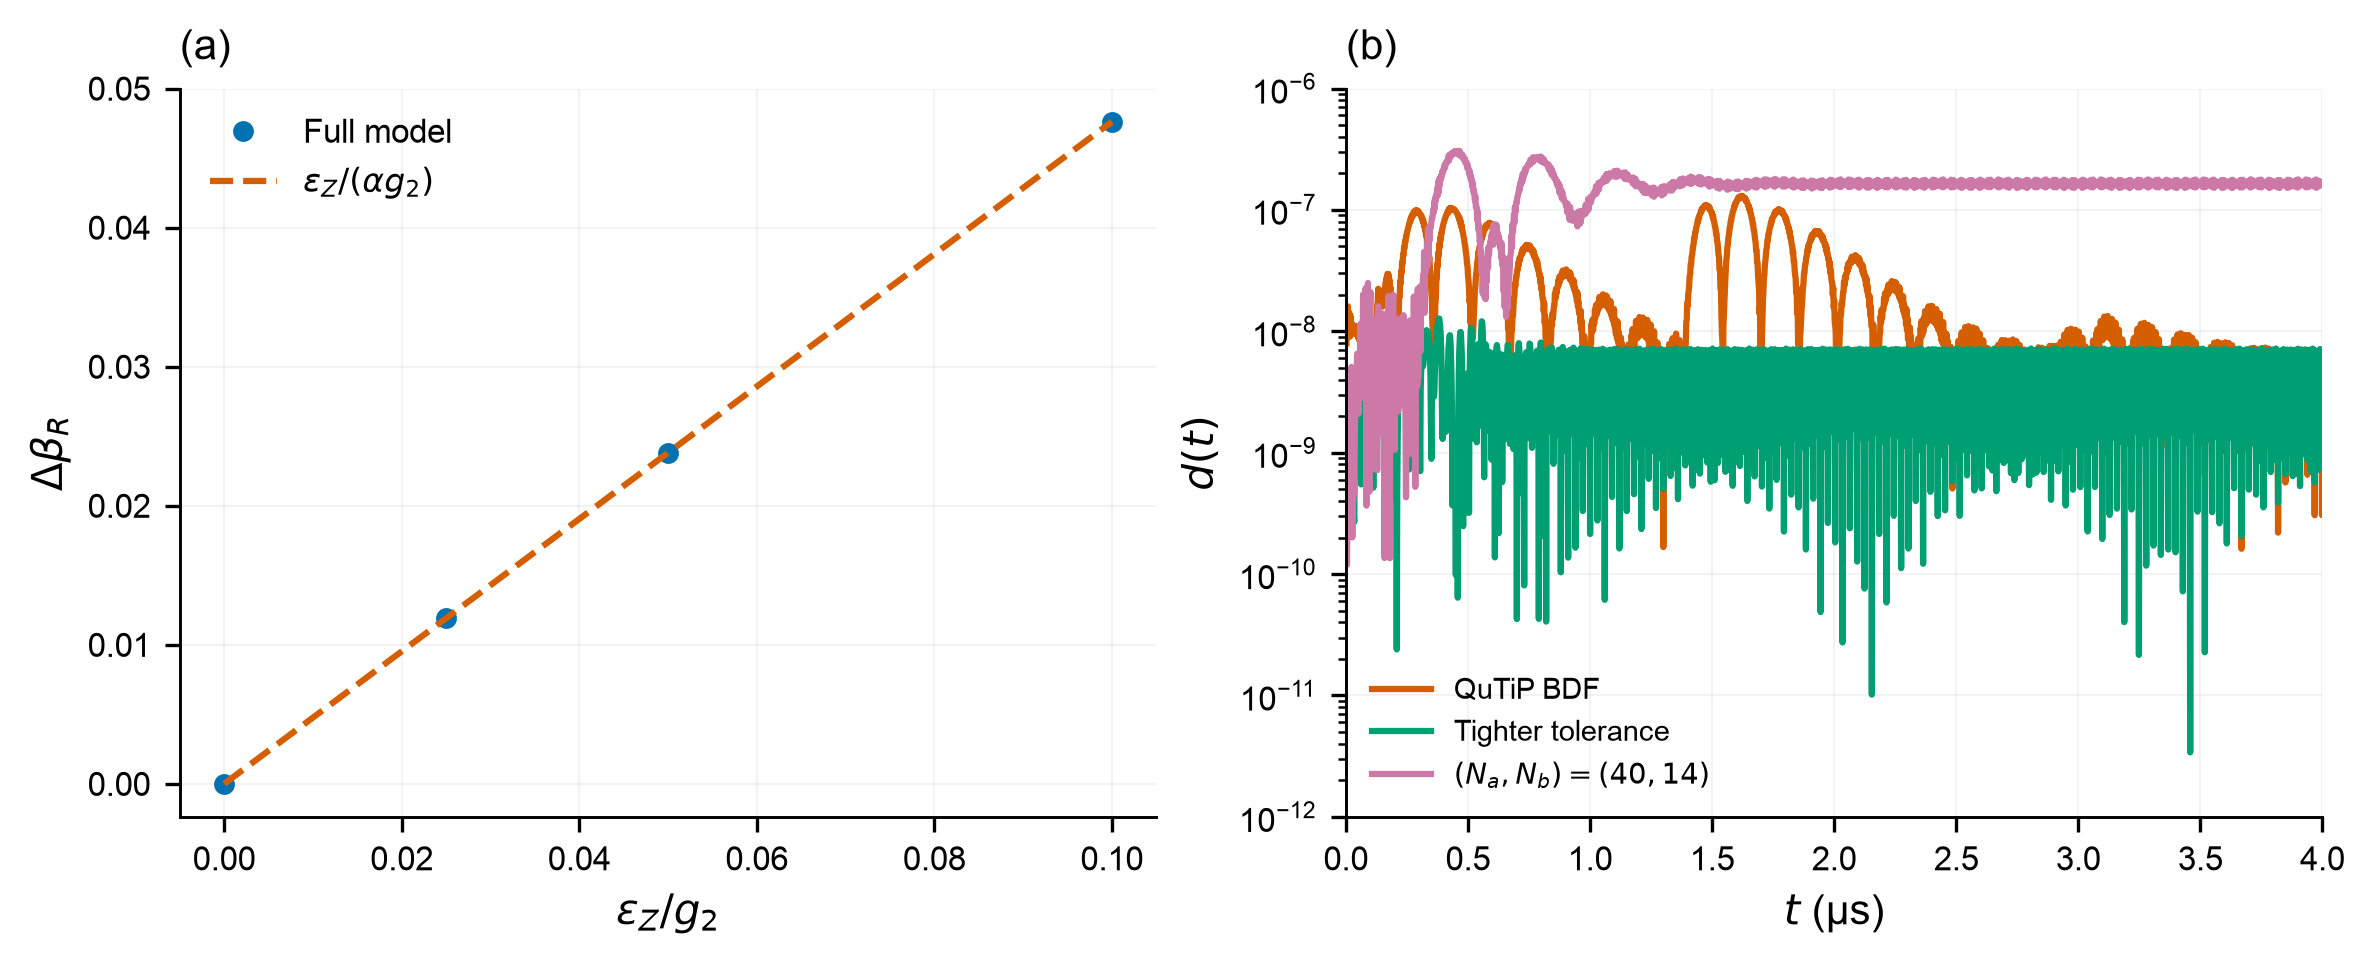

In [6]:
show('task_2_3_validation')

**Readout linearity and numerical checks.** (a) Plateau contrast $\Delta\beta_R=\mathrm{Re}(\bar\beta_--\bar\beta_+)$ from 3–4 µs means versus $\epsilon_Z/g_2$, including zero drive. Dashes give $\epsilon_Z/(\alpha g_2)$. (b) Normalized difference $d(t)=\max_s|\beta_s^{\mathrm{ref}}(t)-\beta_s(t)|/[\epsilon_Z/(2\alpha g_2)]$ at the nominal drive $\epsilon_Z/g_2=0.05$. References are independent QuTiP BDF and tighter Tsit5 integration at the production cutoff $(32,12)$, and a joint cutoff increase to $(40,14)$; all physical parameters are shared. Separate memory/buffer cutoff increases and an 8-µs horizon check are reported in the numerical table.

In [7]:
rows = []
for row in r['drive_summaries']:
    rows.append({'epsilon_Z/g2': row['drive_ratio'], 'real separation': row['real_separation'],
                 'linear prediction': row['leading_separation'],
                 'relative difference (%)': None if row['relative_contrast_error'] is None else 100*row['relative_contrast_error'],
                 'settling time (us)': row['settling_time_us']})
display(pd.DataFrame(rows).style.format(precision=6, na_rep='—'))
cutoffs = pd.DataFrame(r['validation']['cutoffs']).rename(columns={
    'max_complex_field_difference_fraction': 'max field difference / half contrast',
    'relative_contrast_difference': 'relative contrast difference',
    'max_memory_top2': 'max top-2 (a)', 'max_buffer_top': 'max top (b)'})
display(cutoffs.style.format({col: '{:.2e}' for col in cutoffs if col not in ['Na', 'Nb']}))
display(pd.DataFrame(r['validation']['checks'].items(), columns=['check', 'passed']))

v = r['validation']
display(Markdown(
    f"Maximum field differences, normalized by the predicted half contrast: "
    f"**{v['tight_solver_max_field_difference_fraction']:.2e}** for tighter Tsit5 and "
    f"**{v['independent_qutip']['max_field_error_fraction']:.2e}** for independent BDF. "
    f"The change between the 3–4 and 7–8 µs plateaus is "
    f"**{v['extended_8us']['plateau_change_fraction']:.2e}**."
))


,epsilon_Z/g2,real separation,linear prediction,relative difference (%),settling time (us)
0,0.000000,0.000000,0.000000,—,—
1,0.025000,0.011895,0.011905,-0.081015,0.976000
2,0.050000,0.023790,0.023810,-0.083362,0.968000
3,0.100000,0.047575,0.047619,-0.092857,0.966000


,Na,Nb,max field difference / half contrast,relative contrast difference,max top-2 (a),max top (b)
0,24,8,1.02e-05,2.94e-07,7.76e-09,2.93e-08
1,40,12,6.53e-08,5.52e-10,1.74e-09,6.84e-10
2,32,14,3.54e-07,5.86e-09,1.27e-09,1.81e-10
3,40,14,3.07e-07,5.24e-09,1.80e-09,1.88e-10


,check,passed
0,opposite_real_fields,True
1,conjugation_symmetry,True
2,zero_drive_has_no_real_contrast,True
3,weak_drive_linearity,True
4,leading_prediction_within_one_percent,True
5,damped_oscillation_resolved,True
6,settles_before_plateau_window,True
7,late_drift_below_point_one_percent,True
8,cutoff_fields_converged,True
9,boundary_populations_small,True


Maximum field differences, normalized by the predicted half contrast: **1.27e-08** for tighter Tsit5 and **1.31e-07** for independent BDF. The change between the 3–4 and 7–8 µs plateaus is **2.44e-05**.

The checks increase the memory and buffer cutoffs separately and jointly, tighten integration tolerances, refine the output grid, test codeword conjugation symmetry and zero drive, and extend the horizon to 8 µs. Independent QuTiP BDF uses separately constructed operators at the same $(32,12)$ cutoff. Trace and final-state spectrum checks retain signed numerical residuals.

The result files contain trajectories, thresholds, numerical differences, versions and source hashes. Recompute with `python -m tasks.task_2_3`; redraw with `--plot-only`; refresh the analysis with `--reanalyze`. Fresh analysis and reanalysis update the plateau-window metadata, derived flux and checks together. References must cover their full required interval. The notebook loads saved results by default; `RERUN=True` performs the full simulation and validation again.

## Interpretation

The two codewords yield opposite real mean fields, consistent with the linear estimate. The conservative drive remains in the tested linear regime. Damped oscillation precedes sustained 1% settling at 0.968 µs; this is a turn-on settling time for the conditional mean response.

Single-shot fidelity and integration time require a measurement-noise model, including detector efficiency and output records. The finite-window plateaus can also lose their codeword dependence after eventual memory switching. Stronger-drive readout and its trade-off with bit-flip protection belong to Task 2.4.

The leading readout estimate and buffer-fluorescence mechanism follow [Réglade et al., Supplement S8.5](https://arxiv.org/html/2307.06617v2). The [report](../docs/task_2_3_readout.md) gives the derivation and full numerical evidence.